> **Disclaimer:** For learning purposes only. "Trello" is used purely as an illustrative scenario. All events, users, metrics, and results in this notebook are hypothetical, synthetic, and fabricated, and do not reflect any real company's data, performance, or practices. No affiliation with or endorsement by Trello is implied.

In [74]:
import pandas as pd 
import numpy as np

In [75]:
data_dict = pd.read_csv("data/events_data_dictionary.csv")
events = pd.read_csv("data/trello_onboarding_events.csv", parse_dates=["timestamp"])


# events.head().T 

Question :
It's early October. The PM says: "Onboarding conversion feels low. We can ship one fix this sprint. Where should we focus?"

In [76]:
events[events['user_id'] == 'u_005207'].sort_values(by='timestamp').T

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
event_id,e_0000002,e_0000003,e_0000004,e_0000005,e_0000006,e_0000007,e_0000008,e_0000009,e_0000010,e_0000011,e_0000012,e_0000013,e_0000014,e_0000015,e_0000016,e_0000017,e_0000018,e_0000019,e_0000020,e_0000021
timestamp,2026-09-01 00:01:43+00:00,2026-09-01 00:01:59+00:00,2026-09-01 00:02:05+00:00,2026-09-01 00:02:12+00:00,2026-09-01 00:02:24+00:00,2026-09-01 00:02:37+00:00,2026-09-01 00:02:42+00:00,2026-09-01 00:02:57+00:00,2026-09-01 00:03:01+00:00,2026-09-01 00:03:09+00:00,2026-09-01 00:04:38+00:00,2026-09-01 00:04:45+00:00,2026-09-01 00:04:50+00:00,2026-09-01 00:04:53+00:00,2026-09-01 00:05:02+00:00,2026-09-01 00:05:38+00:00,2026-09-01 00:05:50+00:00,2026-09-01 00:06:09+00:00,2026-09-01 00:06:28+00:00,2026-09-01 00:06:32+00:00
user_id,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207,u_005207
session_id,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207,s_005207
event_name,landing_page_viewed,signup_clicked,signup_method_selected,onboarding_tutorial_started,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_tutorial_step_completed,onboarding_close_clicked,email_verification_started,email_verification_resend_clicked,email_verification_code_submitted,email_verification_code_submitted,account_created,first_board_reached
device_type,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile,mobile
platform,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android
browser,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome,chrome
os,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android,android
traffic_source,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct,direct


In [77]:
funnel =events.groupby(['event_name','step_number','step_name']).agg(distinct_users = ('user_id','nunique')).sort_values(
    ['step_number']
).reset_index()
funnel

,event_name,step_number,step_name,distinct_users
0,onboarding_close_clicked,1.0,add_first_todo,22
1,onboarding_tutorial_step_completed,1.0,add_first_todo,1669
2,onboarding_tutorial_started,1.0,add_first_todo,1732
3,onboarding_close_clicked,2.0,add_more_todos,25
4,onboarding_tutorial_step_completed,2.0,add_more_todos,1586
5,onboarding_back_clicked,2.0,add_more_todos,91
6,onboarding_back_clicked,3.0,review_todo_list,70
7,onboarding_close_clicked,3.0,review_todo_list,23
8,onboarding_tutorial_step_completed,3.0,review_todo_list,1491
9,onboarding_tutorial_step_completed,4.0,forward_emails_to_trello,1383


In [78]:
funnel =funnel[~funnel['event_name'].isin(['onboarding_close_clicked','onboarding_back_clicked'])]
funnel = funnel.sort_values(['step_number','event_name'])
funnel

,event_name,step_number,step_name,distinct_users
2,onboarding_tutorial_started,1.0,add_first_todo,1732
1,onboarding_tutorial_step_completed,1.0,add_first_todo,1669
4,onboarding_tutorial_step_completed,2.0,add_more_todos,1586
8,onboarding_tutorial_step_completed,3.0,review_todo_list,1491
9,onboarding_tutorial_step_completed,4.0,forward_emails_to_trello,1383
13,onboarding_tutorial_step_completed,5.0,capture_success,1320
15,onboarding_tutorial_step_completed,6.0,first_board_view,1288
17,onboarding_tutorial_step_completed,7.0,move_task_to_today,1063
22,onboarding_tutorial_step_completed,8.0,staying_organized,995
24,onboarding_tutorial_step_completed,9.0,mark_first_todo,944


In [79]:
total_users = funnel['distinct_users'].iloc[0]


funnel['pct_of_total'] = (funnel['distinct_users'] / total_users * 100).round(1)


funnel
#  i see biggest drops as froms tep 6-7 

,event_name,step_number,step_name,distinct_users,pct_of_total
2,onboarding_tutorial_started,1.0,add_first_todo,1732,100.0
1,onboarding_tutorial_step_completed,1.0,add_first_todo,1669,96.4
4,onboarding_tutorial_step_completed,2.0,add_more_todos,1586,91.6
8,onboarding_tutorial_step_completed,3.0,review_todo_list,1491,86.1
9,onboarding_tutorial_step_completed,4.0,forward_emails_to_trello,1383,79.8
13,onboarding_tutorial_step_completed,5.0,capture_success,1320,76.2
15,onboarding_tutorial_step_completed,6.0,first_board_view,1288,74.4
17,onboarding_tutorial_step_completed,7.0,move_task_to_today,1063,61.4
22,onboarding_tutorial_step_completed,8.0,staying_organized,995,57.4
24,onboarding_tutorial_step_completed,9.0,mark_first_todo,944,54.5


In [80]:
funnel_device = (
    events[~events['event_name'].isin(['onboarding_close_clicked', 'onboarding_back_clicked'])]
    .groupby(['device_type', 'event_name', 'step_number', 'step_name'])
    .agg(distinct_users=('user_id', 'nunique'))
    .reset_index()
    .sort_values(['device_type', 'step_number', 'event_name'])
)

# total per device = users at the first step (tutorial started) within that device
device_total = funnel_device.groupby('device_type')['distinct_users'].transform('first')
funnel_device['pct_of_total'] = (funnel_device['distinct_users'] / device_total * 100).round(1)

funnel_device[funnel_device['step_number'].isin([6,7])]

,device_type,event_name,step_number,step_name,distinct_users,pct_of_total
6,desktop,onboarding_tutorial_step_completed,6.0,first_board_view,742,76.3
7,desktop,onboarding_tutorial_step_completed,7.0,move_task_to_today,659,67.7
17,mobile,onboarding_tutorial_step_completed,6.0,first_board_view,477,70.9
18,mobile,onboarding_tutorial_step_completed,7.0,move_task_to_today,345,51.3
28,tablet,onboarding_tutorial_step_completed,6.0,first_board_view,69,80.2
29,tablet,onboarding_tutorial_step_completed,7.0,move_task_to_today,59,68.6


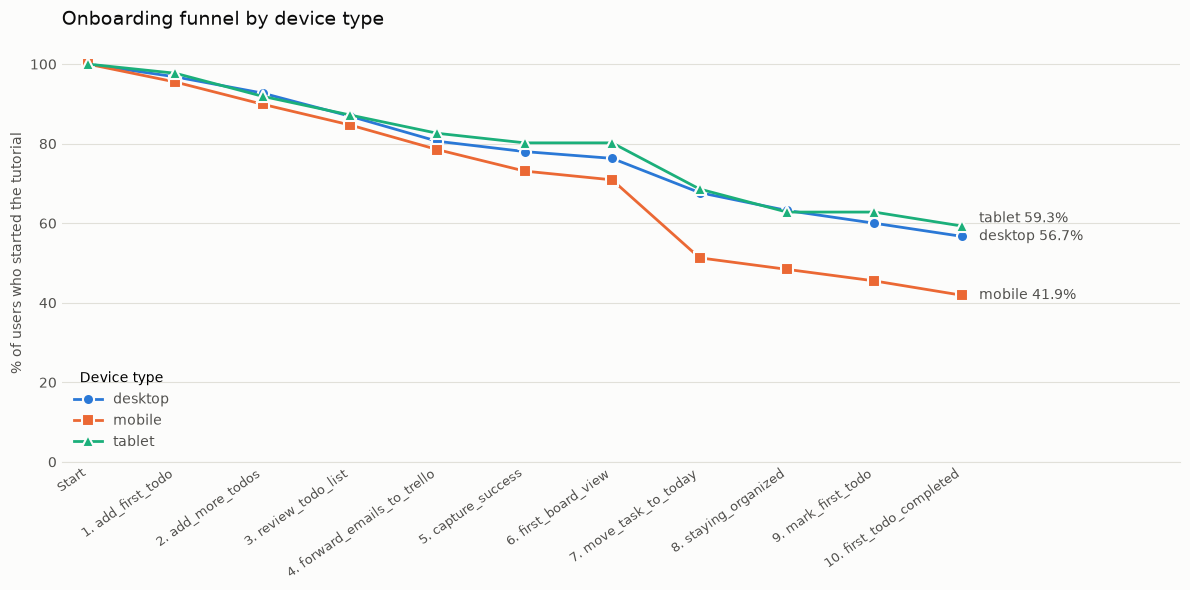

In [81]:
import matplotlib.pyplot as plt

SURFACE, GRID, TEXT, TEXT_2 = "#fcfcfb", "#e1e0d9", "#0b0b0b", "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # dataviz categorical slots 1-3 (blue, orange, aqua)
MARKERS = ["o", "s", "^"]                    # shape as secondary encoding (color-blind safe)

plot_df = funnel_device.copy()
plot_df["label"] = np.where(
    plot_df["event_name"] == "onboarding_tutorial_started",
    "Start",
    plot_df["step_number"].astype(int).astype(str) + ". " + plot_df["step_name"],
)
order = plot_df.drop_duplicates("label").sort_values(["step_number", "event_name"])["label"].tolist()
wide = plot_df.pivot(index="label", columns="device_type", values="pct_of_total").loc[order]

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

x = range(len(wide))
for i, device in enumerate(wide.columns):
    ax.plot(x, wide[device], color=SERIES[i], marker=MARKERS[i], linewidth=2, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=device, zorder=3)

# direct labels at the line ends, nudged apart if they would collide
ends = wide.iloc[-1].sort_values()
ypos, min_gap = {}, 4.5
prev = None
for device, val in ends.items():
    y = val if prev is None else max(val, prev + min_gap)
    ypos[device], prev = y, y
for device, y in ypos.items():
    ax.text(len(wide) - 1 + 0.2, y, f"{device} {ends[device]:.1f}%", color=TEXT_2, fontsize=10, va="center")

ax.set_xticks(list(x))
ax.set_xticklabels(order, rotation=35, ha="right", color=TEXT_2, fontsize=9)
ax.set_xlim(-0.3, len(wide) + 1.5)
ax.set_ylim(0, 105)
ax.set_ylabel("% of users who started the tutorial", color=TEXT_2)
ax.set_title("Onboarding funnel by device type", color=TEXT, fontsize=14, loc="left", pad=14)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=TEXT_2, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(title="Device type", frameon=False, labelcolor=TEXT_2, loc="lower left")

plt.tight_layout()
plt.show()

In [82]:
funnel_mobile = (
    events[
        (events['device_type'] == 'mobile')
        & ~events['event_name'].isin(['onboarding_close_clicked', 'onboarding_back_clicked'])
    ]
    .groupby(['traffic_source', 'event_name', 'step_number', 'step_name'])
    .agg(distinct_users=('user_id', 'nunique'))
    .reset_index()
    .sort_values(['traffic_source', 'step_number', 'event_name'])
)

# total per traffic source = mobile users at the first step (tutorial started) within that source
source_total = funnel_mobile.groupby('traffic_source')['distinct_users'].transform('first')
funnel_mobile['pct_of_total'] = (funnel_mobile['distinct_users'] / source_total * 100).round(1)

# side by side: one row per step, one column per traffic source
funnel_mobile.pivot(
    index=['step_number', 'step_name', 'event_name'],
    columns='traffic_source',
    values=['distinct_users', 'pct_of_total'],
)

distinct_users  \
traffic_source                                                                  direct   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                 147.0   
                                     onboarding_tutorial_step_completed          135.0   
2.0         add_more_todos           onboarding_tutorial_step_completed          126.0   
3.0         review_todo_list         onboarding_tutorial_step_completed          119.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed          107.0   
5.0         capture_success          onboarding_tutorial_step_completed          104.0   
6.0         first_board_view         onboarding_tutorial_step_completed          102.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed           72.0   
8.0         staying_organized        onboarding_tutorial_step_completed           67.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed           60.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           51.0   

                                                                                        \
traffic_source                                                          email_campaign   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                  88.0   
                                     onboarding_tutorial_step_completed           84.0   
2.0         add_more_todos           onboarding_tutorial_step_completed           81.0   
3.0         review_todo_list         onboarding_tutorial_step_completed           76.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed           70.0   
5.0         capture_success          onboarding_tutorial_step_completed           65.0   
6.0         first_board_view         onboarding_tutorial_step_completed           61.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed           44.0   
8.0         staying_organized        onboarding_tutorial_step_completed           43.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed           38.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           35.0   

                                                                                    \
traffic_source                                                          google_ads   
step_number step_name                event_name                                      
1.0         add_first_todo           onboarding_tutorial_started             106.0   
                                     onboarding_tutorial_step_completed       99.0   
2.0         add_more_todos           onboarding_tutorial_step_completed       91.0   
3.0         review_todo_list         onboarding_tutorial_step_completed       86.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed       83.0   
5.0         capture_success          onboarding_tutorial_step_completed       76.0   
6.0         first_board_view         onboarding_tutorial_step_completed       75.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed       57.0   
8.0         staying_organized        onboarding_tutorial_step_completed       54.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed       53.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed       50.0   

                                                                                        \
traffic_source                                                          organic_search   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started           

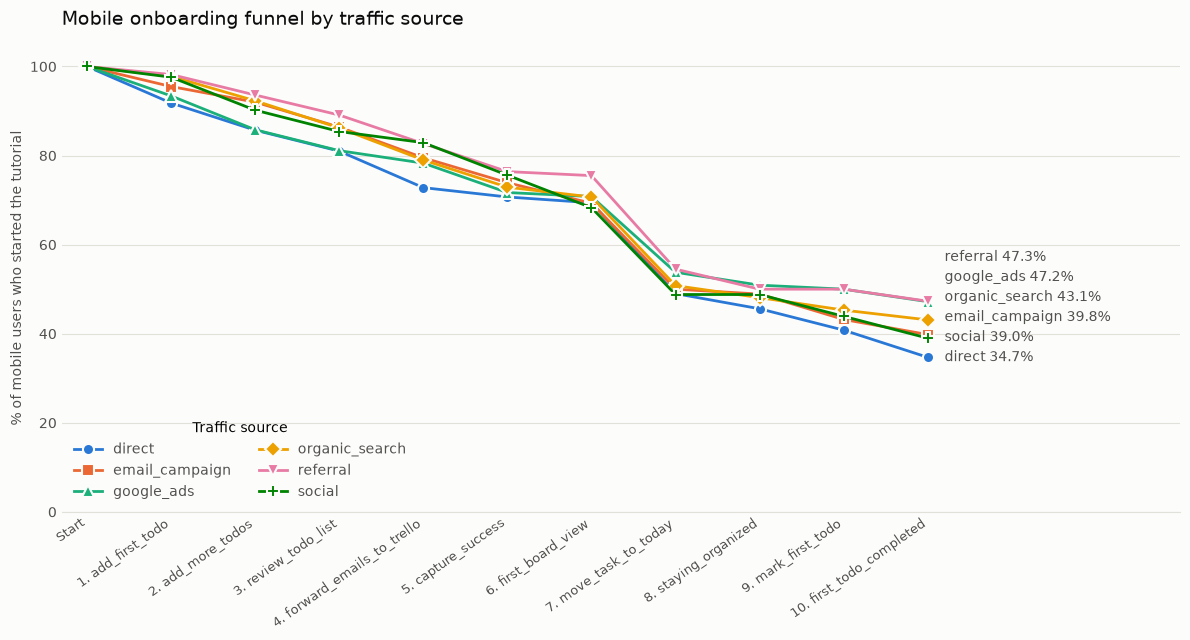

In [83]:
sources = sorted(funnel_mobile['traffic_source'].unique())
# dataviz categorical slots 1-6 (blue, orange, aqua, yellow, magenta, green), fixed per source
SRC_COLORS = dict(zip(sources, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
SRC_MARKERS = dict(zip(sources, ["o", "s", "^", "D", "v", "P"]))

plot_m = funnel_mobile.copy()
plot_m["label"] = np.where(
    plot_m["event_name"] == "onboarding_tutorial_started",
    "Start",
    plot_m["step_number"].astype(int).astype(str) + ". " + plot_m["step_name"],
)
order = plot_m.drop_duplicates("label").sort_values(["step_number", "event_name"])["label"].tolist()
wide_m = plot_m.pivot(index="label", columns="traffic_source", values="pct_of_total").loc[order]

fig, ax = plt.subplots(figsize=(12, 6.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

x = range(len(wide_m))
for src in wide_m.columns:
    ax.plot(x, wide_m[src], color=SRC_COLORS[src], marker=SRC_MARKERS[src], linewidth=2, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=src, zorder=3)

# direct labels at the line ends, nudged apart if they would collide
ends = wide_m.iloc[-1].sort_values()
ypos, min_gap, prev = {}, 4.5, None
for src, val in ends.items():
    y = val if prev is None else max(val, prev + min_gap)
    ypos[src], prev = y, y
for src, y in ypos.items():
    ax.text(len(wide_m) - 1 + 0.2, y, f"{src} {ends[src]:.1f}%", color=TEXT_2, fontsize=10, va="center")

ax.set_xticks(list(x))
ax.set_xticklabels(order, rotation=35, ha="right", color=TEXT_2, fontsize=9)
ax.set_xlim(-0.3, len(wide_m) + 2)
ax.set_ylim(0, 105)
ax.set_ylabel("% of mobile users who started the tutorial", color=TEXT_2)
ax.set_title("Mobile onboarding funnel by traffic source", color=TEXT, fontsize=14, loc="left", pad=14)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=TEXT_2, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(title="Traffic source", frameon=False, labelcolor=TEXT_2, loc="lower left", ncol=2)

plt.tight_layout()
plt.show()

In [84]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # dataviz categorical slots 1-6
MARKER_SET = ["o", "s", "^", "D", "v", "P"]


def mobile_funnel(by, **filters):
    """Mobile-only funnel (plus any extra column=value filters), one row per (group, step),
    pct_of_total vs. that group's tutorial-started users."""
    mask = (events['device_type'] == 'mobile') & ~events['event_name'].isin(
        ['onboarding_close_clicked', 'onboarding_back_clicked']
    )
    for col, val in filters.items():
        mask &= events[col] == val
    df = (
        events[mask]
        .groupby([by, 'event_name', 'step_number', 'step_name'])
        .agg(distinct_users=('user_id', 'nunique'))
        .reset_index()
        .sort_values([by, 'step_number', 'event_name'])
    )
    total = df.groupby(by)['distinct_users'].transform('first')
    df['pct_of_total'] = (df['distinct_users'] / total * 100).round(1)
    return df


def funnel_table(df, by):
    return df.pivot(
        index=['step_number', 'step_name', 'event_name'],
        columns=by,
        values=['distinct_users', 'pct_of_total'],
    )


def plot_funnel(df, by, title, legend_title, ylabel="% of mobile users who started the tutorial"):
    groups = sorted(df[by].unique())
    colors = dict(zip(groups, PALETTE))     # fixed per group, never by rank
    markers = dict(zip(groups, MARKER_SET))

    d = df.copy()
    d["label"] = np.where(
        d["event_name"] == "onboarding_tutorial_started",
        "Start",
        d["step_number"].astype(int).astype(str) + ". " + d["step_name"],
    )
    order = d.drop_duplicates("label").sort_values(["step_number", "event_name"])["label"].tolist()
    wide = d.pivot(index="label", columns=by, values="pct_of_total").loc[order]

    fig, ax = plt.subplots(figsize=(12, 6), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    x = range(len(wide))
    for g in wide.columns:
        ax.plot(x, wide[g], color=colors[g], marker=markers[g], linewidth=2, markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=g, zorder=3)

    # direct labels at the line ends, nudged apart if they would collide
    ends = wide.iloc[-1].sort_values()
    ypos, min_gap, prev = {}, 4.5, None
    for g, val in ends.items():
        y = val if prev is None else max(val, prev + min_gap)
        ypos[g], prev = y, y
    for g, y in ypos.items():
        ax.text(len(wide) - 1 + 0.2, y, f"{g} {ends[g]:.1f}%", color=TEXT_2, fontsize=10, va="center")

    ax.set_xticks(list(x))
    ax.set_xticklabels(order, rotation=35, ha="right", color=TEXT_2, fontsize=9)
    ax.set_xlim(-0.3, len(wide) + 2)
    ax.set_ylim(0, 105)
    ax.set_ylabel(ylabel, color=TEXT_2)
    ax.set_title(title, color=TEXT, fontsize=14, loc="left", pad=14)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(colors=TEXT_2, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.legend(title=legend_title, frameon=False, labelcolor=TEXT_2, loc="lower left")
    plt.tight_layout()
    plt.show()

In [85]:
funnel_segment = mobile_funnel('user_segment')
funnel_table(funnel_segment, 'user_segment')

distinct_users  \
user_segment                                                              invited_user   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                 177.0   
                                     onboarding_tutorial_step_completed          171.0   
2.0         add_more_todos           onboarding_tutorial_step_completed          163.0   
3.0         review_todo_list         onboarding_tutorial_step_completed          154.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed          142.0   
5.0         capture_success          onboarding_tutorial_step_completed          135.0   
6.0         first_board_view         onboarding_tutorial_step_completed          130.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed          106.0   
8.0         staying_organized        onboarding_tutorial_step_completed          103.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed          101.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           96.0   

                                                                                  \
user_segment                                                            new_user   
step_number step_name                event_name                                    
1.0         add_first_todo           onboarding_tutorial_started           496.0   
                                     onboarding_tutorial_step_completed    472.0   
2.0         add_more_todos           onboarding_tutorial_step_completed    442.0   
3.0         review_todo_list         onboarding_tutorial_step_completed    416.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed    386.0   
5.0         capture_success          onboarding_tutorial_step_completed    357.0   
6.0         first_board_view         onboarding_tutorial_step_completed    347.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed    239.0   
8.0         staying_organized        onboarding_tutorial_step_completed    223.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed    205.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed    186.0   

                                                                        pct_of_total  \
user_segment                                                            invited_user   
step_number step_name                event_name                                        
1.0         add_first_todo           onboarding_tutorial_started               100.0   
                                     onboarding_tutorial_step_completed         96.6   
2.0         add_more_todos           onboarding_tutorial_step_completed         92.1   
3.0         review_todo_list         onboarding_tutorial_step_completed         87.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed         80.2   
5.0         capture_success          onboarding_tutorial_step_completed         76.3   
6.0         first_board_view         onboarding_tutorial_step_completed         73.4   
7.0         move_task_to_today       onboarding_tutorial_step_completed         59.9   
8.0         staying_organized        onboarding_tutorial_step_completed         58.2   
9.0         mark_first_todo          onboarding_tutorial_step_completed         57.1   
10.0        first_todo_completed     onboarding_tutorial_step_completed         54.2   

                                                                                  
user_segment                                                            new_user  
step_number step_name                event_name                                   
1.0         add_first_todo           onboarding_tutorial_started           100.0  
                                     onboarding_tutorial_step_complet

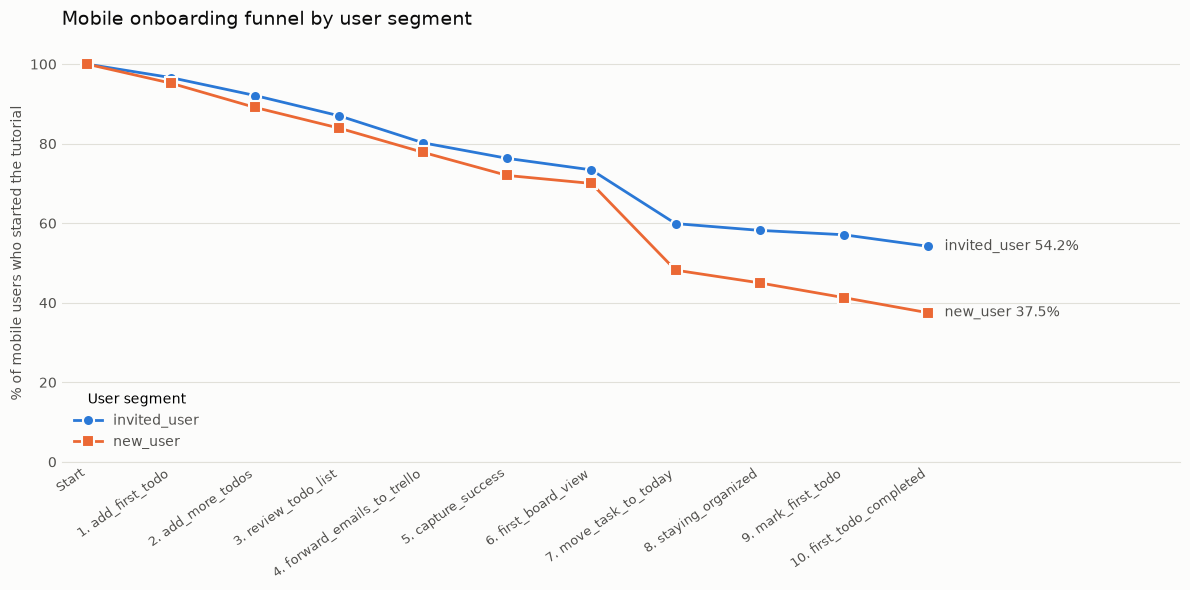

In [86]:
plot_funnel(funnel_segment, 'user_segment', 'Mobile onboarding funnel by user segment', 'User segment')

In [87]:
funnel_signup = mobile_funnel('signup_method')
funnel_table(funnel_signup, 'signup_method')

distinct_users  \
signup_method                                                                    apple   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                  42.0   
                                     onboarding_tutorial_step_completed           41.0   
2.0         add_more_todos           onboarding_tutorial_step_completed           39.0   
3.0         review_todo_list         onboarding_tutorial_step_completed           38.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed           37.0   
5.0         capture_success          onboarding_tutorial_step_completed           34.0   
6.0         first_board_view         onboarding_tutorial_step_completed           31.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed           23.0   
8.0         staying_organized        onboarding_tutorial_step_completed           22.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed           22.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           21.0   

                                                                                \
signup_method                                                            email   
step_number step_name                event_name                                  
1.0         add_first_todo           onboarding_tutorial_started         348.0   
                                     onboarding_tutorial_step_completed  332.0   
2.0         add_more_todos           onboarding_tutorial_step_completed  314.0   
3.0         review_todo_list         onboarding_tutorial_step_completed  296.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed  272.0   
5.0         capture_success          onboarding_tutorial_step_completed  249.0   
6.0         first_board_view         onboarding_tutorial_step_completed  242.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed  172.0   
8.0         staying_organized        onboarding_tutorial_step_completed  159.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed  148.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed  134.0   

                                                                                \
signup_method                                                           google   
step_number step_name                event_name                                  
1.0         add_first_todo           onboarding_tutorial_started         208.0   
                                     onboarding_tutorial_step_completed  199.0   
2.0         add_more_todos           onboarding_tutorial_step_completed  184.0   
3.0         review_todo_list         onboarding_tutorial_step_completed  172.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed  158.0   
5.0         capture_success          onboarding_tutorial_step_completed  151.0   
6.0         first_board_view         onboarding_tutorial_step_completed  147.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed  109.0   
8.0         staying_organized        onboarding_tutorial_step_completed  106.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed  100.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed   93.0   

                                                                                   \
signup_method                                                           microsoft   
step_number step_name                event_name                                     
1.0         add_first_todo           onboarding_tutorial_started             64.0   
                                     onboarding_tutorial_step_completed      60.0   
2.0         add_more_todos           onboarding_tutorial_step_completed      58.0   
3.0

In [88]:
funnel_signup[funnel_signup['step_number'].isin([6,7])]

,signup_method,event_name,step_number,step_name,distinct_users,pct_of_total
6,apple,onboarding_tutorial_step_completed,6.0,first_board_view,31,73.8
7,apple,onboarding_tutorial_step_completed,7.0,move_task_to_today,23,54.8
17,email,onboarding_tutorial_step_completed,6.0,first_board_view,242,69.5
18,email,onboarding_tutorial_step_completed,7.0,move_task_to_today,172,49.4
28,google,onboarding_tutorial_step_completed,6.0,first_board_view,147,70.7
29,google,onboarding_tutorial_step_completed,7.0,move_task_to_today,109,52.4
39,microsoft,onboarding_tutorial_step_completed,6.0,first_board_view,49,76.6
40,microsoft,onboarding_tutorial_step_completed,7.0,move_task_to_today,33,51.6
50,slack,onboarding_tutorial_step_completed,6.0,first_board_view,8,72.7
51,slack,onboarding_tutorial_step_completed,7.0,move_task_to_today,8,72.7


In [89]:
funnel_new_src = mobile_funnel('traffic_source', user_segment='new_user')
funnel_table(funnel_new_src, 'traffic_source')

distinct_users  \
traffic_source                                                                  direct   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                 112.0   
                                     onboarding_tutorial_step_completed          105.0   
2.0         add_more_todos           onboarding_tutorial_step_completed           98.0   
3.0         review_todo_list         onboarding_tutorial_step_completed           91.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed           81.0   
5.0         capture_success          onboarding_tutorial_step_completed           79.0   
6.0         first_board_view         onboarding_tutorial_step_completed           78.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed           52.0   
8.0         staying_organized        onboarding_tutorial_step_completed           48.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed           43.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           34.0   

                                                                                        \
traffic_source                                                          email_campaign   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started                  63.0   
                                     onboarding_tutorial_step_completed           59.0   
2.0         add_more_todos           onboarding_tutorial_step_completed           58.0   
3.0         review_todo_list         onboarding_tutorial_step_completed           53.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed           49.0   
5.0         capture_success          onboarding_tutorial_step_completed           47.0   
6.0         first_board_view         onboarding_tutorial_step_completed           43.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed           29.0   
8.0         staying_organized        onboarding_tutorial_step_completed           28.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed           23.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed           21.0   

                                                                                    \
traffic_source                                                          google_ads   
step_number step_name                event_name                                      
1.0         add_first_todo           onboarding_tutorial_started              83.0   
                                     onboarding_tutorial_step_completed       76.0   
2.0         add_more_todos           onboarding_tutorial_step_completed       69.0   
3.0         review_todo_list         onboarding_tutorial_step_completed       65.0   
4.0         forward_emails_to_trello onboarding_tutorial_step_completed       63.0   
5.0         capture_success          onboarding_tutorial_step_completed       57.0   
6.0         first_board_view         onboarding_tutorial_step_completed       57.0   
7.0         move_task_to_today       onboarding_tutorial_step_completed       41.0   
8.0         staying_organized        onboarding_tutorial_step_completed       40.0   
9.0         mark_first_todo          onboarding_tutorial_step_completed       39.0   
10.0        first_todo_completed     onboarding_tutorial_step_completed       36.0   

                                                                                        \
traffic_source                                                          organic_search   
step_number step_name                event_name                                          
1.0         add_first_todo           onboarding_tutorial_started           

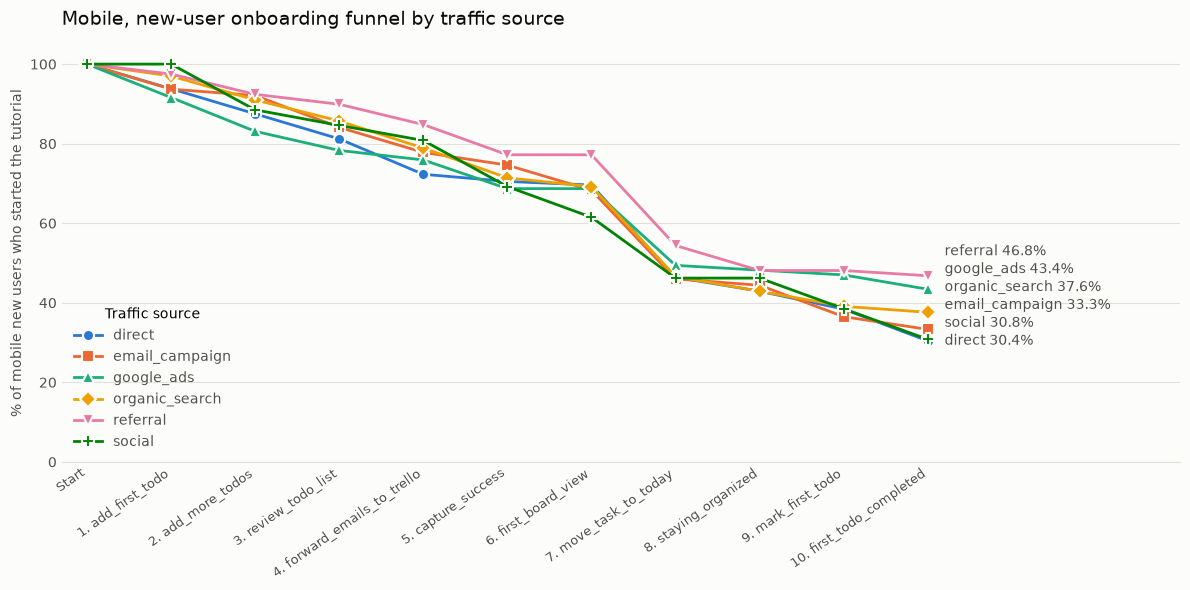

In [90]:
plot_funnel(
    funnel_new_src, 'traffic_source',
    'Mobile, new-user onboarding funnel by traffic source', 'Traffic source',
    ylabel="% of mobile new users who started the tutorial",
)

In [93]:
funnel_final = (
    events[(events['device_type'] == 'mobile') & (events['user_segment'] == 'new_user')]
    .groupby(['traffic_source','event_name', 'step_number', 'step_name'])
    .agg(distinct_users=('user_id', 'nunique'))
    .sort_values(['step_number'])
    .reset_index()
)


In [94]:
funnel_final

,traffic_source,event_name,step_number,step_name,distinct_users
0,google_ads,onboarding_tutorial_step_completed,1.0,add_first_todo,76
1,email_campaign,onboarding_close_clicked,1.0,add_first_todo,2
2,email_campaign,onboarding_tutorial_started,1.0,add_first_todo,63
3,email_campaign,onboarding_tutorial_step_completed,1.0,add_first_todo,59
4,google_ads,onboarding_close_clicked,1.0,add_first_todo,2
...,...,...,...,...,...
132,referral,onboarding_tutorial_step_completed,10.0,first_todo_completed,37
133,google_ads,onboarding_tutorial_step_completed,10.0,first_todo_completed,36
134,email_campaign,onboarding_tutorial_step_completed,10.0,first_todo_completed,21
135,organic_search,onboarding_back_clicked,10.0,first_todo_completed,4
